# Chapitre 6 - Cours 2 : journaux de réplication et retard des suiveurs

Le cours 1 a traité le journal de réplication comme une boîte noire. Ce cours l'ouvre
(que contient-il exactement ?), puis étudie la conséquence la plus visible de la
réplication asynchrone : des suiveurs **en retard**, qui font voir aux utilisateurs des
choses étranges. Il couvre les sections *Implementation of Replication Logs* et
*Problems with Replication Lag* (*Reading Your Own Writes*, *Monotonic Reads*,
*Consistent Prefix Reads*, *Solutions for Replication Lag*).

**Plan.**

1. Réplication par instructions, et pourquoi elle diverge.
2. Expédition du journal d'écriture anticipée (WAL).
3. Réplication logique, par lignes.
4. Le retard de réplication et la cohérence à terme.
5. Lire ses propres écritures.
6. Lectures monotones.
7. Lectures à préfixe cohérent.
8. Choisir une parade.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Réplication par instructions (section *Statement-based replication*)

L'idée la plus simple : le leader journalise chaque **instruction** d'écriture
(`INSERT`, `UPDATE`, `DELETE`) et chaque suiveur la ré-exécute comme si un client la lui
avait envoyée. C'est compact, mais cela casse dès qu'une instruction n'est pas
**déterministe** :

- une fonction comme `NOW()` ou `RAND()` donne une valeur différente sur chaque réplique ;
- une instruction qui dépend des données existantes (`UPDATE ... WHERE ...`, une colonne
  auto-incrémentée) doit être exécutée **exactement dans le même ordre** partout, ce qui
  gêne avec des transactions concurrentes ;
- les effets de bord (déclencheurs, procédures stockées, fonctions utilisateur) doivent
  être parfaitement déterministes.

Rejouons-le avec la mini-base `rp.MiniDB` : chaque réplique a sa propre horloge (le
suiveur avance de 0,7 s) et son propre générateur aléatoire. Trois instructions : une
insertion avec `NOW()` et `RAND()`, puis deux transactions concurrentes sur le même
compte (doubler le solde, ajouter 10). Le suiveur reçoit les deux transactions dans
l'ordre inverse, ce qui arrive quand elles se chevauchent sur le leader.

In [2]:
STMTS_SQL = ["INSERT INTO evt (at, tirage) VALUES (NOW(), RAND())",
             "UPDATE comptes SET solde = solde * 2",
             "UPDATE comptes SET solde = solde + 10"]
stmts = [lambda db, t: db.insert("evt", {"at": db.now(t), "tirage": db.rand()}),
         lambda db, t: [db.update("comptes", r["id"], {"solde": r["solde"] * 2}) for r in db.select("comptes")],
         lambda db, t: [db.update("comptes", r["id"], {"solde": r["solde"] + 10}) for r in db.select("comptes")]]

def fresh(name, offset, seed):
    db = rp.MiniDB(name, clock_offset=offset, seed=seed)
    db.insert("comptes", {"id": 1, "solde": 100})
    db.changes.clear()
    return db

def compare(L, F):
    rows = []
    for table in ("evt", "comptes"):
        for pk, row in L.tables[table].items():
            for col, v in row.items():
                if col != "id":
                    w = F.tables[table][pk][col]
                    rows.append({"table": table, "colonne": col, "leader": v, "suiveur": w,
                                 "identique": "oui" if v == w else "NON"})
    return pd.DataFrame(rows)

L, F = fresh("leader", 0.0, 1), fresh("suiveur", 0.7, 2)
rp.replicate_statements(stmts, L, [F], times=[1.0, 2.0, 2.0], follower_order=[[0, 2, 1]])
compare(L, F)

,table,colonne,leader,suiveur,identique
0,evt,at,1.000,1.750,NON
1,evt,tirage,0.134,0.956,NON
2,comptes,solde,210.000,220.000,NON


Les trois valeurs divergent : l'horodatage (horloges différentes), le tirage (générateurs
différents) et le solde, $2 \times 100 + 10 = 210$ sur le leader contre
$2 \times (100 + 10) = 220$ sur le suiveur. Personne n'a signalé d'erreur : les répliques
ont **silencieusement** cessé d'être des copies.

Les parades existent : le leader peut remplacer chaque appel non déterministe par sa
valeur au moment de journaliser l'instruction, et imposer un ordre d'exécution total.
Exécuter des instructions déterministes dans un ordre fixé, c'est la **réplication de
machine à états** (le livre la rapproche de l'event sourcing et y revient avec les journaux partagés). MySQL utilisait la réplication
par instructions avant la version 5.1 et bascule aujourd'hui vers la réplication par
lignes dès qu'une instruction n'est pas déterministe ; VoltDB la rend sûre en exigeant
des transactions déterministes. Mais le déterminisme est difficile à garantir, d'où les
deux autres méthodes.

> **À retenir.** Rejouer les instructions SQL sur chaque réplique est compact, mais toute
> source de non-déterminisme (horloge, hasard, ordre, effets de bord) fait diverger les
> copies sans bruit.

## 2. Expédition du journal d'écriture anticipée (section *Write-ahead log shipping*)

Le moteur de stockage tient déjà un journal : le **WAL** (chapitre 4), où
toute modification est écrite avant d'être appliquée aux pages, pour survivre aux
pannes. Puisque ce journal suffit à reconstruire l'état exact des fichiers, il suffit
de l'envoyer aussi aux suiveurs, qui reconstruisent des fichiers **identiques octet pour
octet**. C'est ce que font PostgreSQL et Oracle.

L'inconvénient : le WAL décrit les données à très bas niveau (« tels octets dans tel bloc
du disque »). La réplication est donc **couplée au format de stockage**. Illustrons-le
avec un enregistrement de WAL « physique » qui écrit un solde dans une page, interprété
par une version du moteur qui a modifié la disposition des pages (un en-tête de ligne
passé de 4 à 8 octets).

In [3]:
import struct

def page_v1(solde):        # en-tête de ligne 4 octets (id), puis solde sur 4 octets
    return bytearray(struct.pack("<ii", 1, solde)) + bytearray(8)

def lire_v1(page):
    return struct.unpack_from("<i", page, 4)[0]

def lire_v2(page):         # version suivante : en-tête de 8 octets (id + drapeaux)
    return struct.unpack_from("<i", page, 8)[0]

wal_record = {"page": 17, "offset": 4, "octets": struct.pack("<i", 210)}   # « écrire 210 à l'octet 4 »
p_leader, p_suiveur = page_v1(100), page_v1(100)
for p in (p_leader, p_suiveur):
    p[wal_record["offset"]:wal_record["offset"] + 4] = wal_record["octets"]
pd.DataFrame({"version du moteur qui lit la page": ["v1 (même version que le leader)", "v2 (moteur mis à jour)"],
              "solde lu": [lire_v1(p_suiveur), lire_v2(p_suiveur)]})

,version du moteur qui lit la page,solde lu
0,v1 (même version que le leader),210
1,v2 (moteur mis à jour),0


Le même enregistrement, appliqué fidèlement, donne un solde de 210 pour un moteur v1 et
une valeur absurde (0) pour un moteur v2 qui cherche le solde 4 octets plus loin. C'est
pourquoi, avec l'expédition du WAL, leader et suiveurs doivent en général tourner
**exactement** la même version du logiciel. Conséquence opérationnelle majeure : pas de
mise à jour sans interruption. Avec un protocole qui tolère un suiveur plus récent, on
mettrait d'abord à jour les suiveurs, puis on basculerait vers l'un d'eux ; avec le WAL,
il faut arrêter le service.

> **À retenir.** Expédier le WAL donne des copies exactes au moindre coût, mais lie la
> réplication au format physique du moteur : versions identiques obligatoires, mises à
> jour avec interruption.

## 3. Réplication logique, par lignes (section *Logical (row-based) log replication*)

Troisième voie : un journal **logique**, distinct du format de stockage, qui décrit les
écritures à la granularité de la ligne :

- insertion : les nouvelles valeurs de toutes les colonnes ;
- suppression : de quoi identifier la ligne (la clé primaire, ou toutes les anciennes
  valeurs s'il n'y en a pas) ;
- mise à jour : l'identifiant de la ligne et les nouvelles valeurs (au moins celles qui
  changent) ;
- une transaction qui touche plusieurs lignes produit plusieurs enregistrements, suivis
  d'un enregistrement de validation.

Le leader exécute l'instruction **une fois**, puis journalise ses **effets** : les
valeurs non déterministes sont figées. Rejouons les trois instructions de la section 1.

In [4]:
L, F = fresh("leader", 0.0, 1), fresh("suiveur", 0.7, 2)
log = rp.replicate_rows(stmts, L, [F], times=[1.0, 2.0, 2.0])
display(pd.DataFrame([{"opération": op, "table": t, "clé": pk, "valeurs": json.dumps(v)} for op, t, pk, v in log]))
compare(L, F)

,opération,table,clé,valeurs
0,insert,evt,1,"{""at"": 1.0, ""tirage"": 0.1344, ""id"": 1}"
1,update,comptes,1,"{""solde"": 200}"
2,update,comptes,1,"{""solde"": 210}"


,table,colonne,leader,suiveur,identique
0,evt,at,1.000,1.000,oui
1,evt,tirage,0.134,0.134,oui
2,comptes,solde,210.000,210.000,oui


Cette fois, tout est identique : le suiveur n'a pas besoin de son horloge ni de son
générateur, il recopie des valeurs. MySQL tient pour cela un journal logique séparé du
WAL, le **binlog** ; PostgreSQL produit la réplication logique en **décodant** son WAL
physique en événements d'insertion, de mise à jour et de suppression (le lab de ce
chapitre le montre avec `test_decoding`).

Deux avantages supplémentaires :

- découplé du moteur, le format logique peut rester **rétrocompatible** : leader et
  suiveurs peuvent tourner des versions différentes, d'où des mises à jour quasi sans
  interruption ;
- il est facile à lire pour d'**autres systèmes** (entrepôt de données, index de
  recherche, cache) : c'est la **capture des changements** (change data capture),
  étudiée au chapitre 12.

**Comparaison des volumes.** Le choix du format change aussi la taille du journal. Une
instruction qui touche $k$ lignes coûte quelques dizaines d'octets en mode instruction,
$k$ enregistrements en mode logique, et en mode WAL au moins les octets modifiés de
chaque page (plus des images de pages complètes après chaque point de contrôle).
Ordres de grandeur (lignes de 100 octets, pages de 8 Ko contenant 80 lignes, image
complète pour 10 % des pages touchées) :

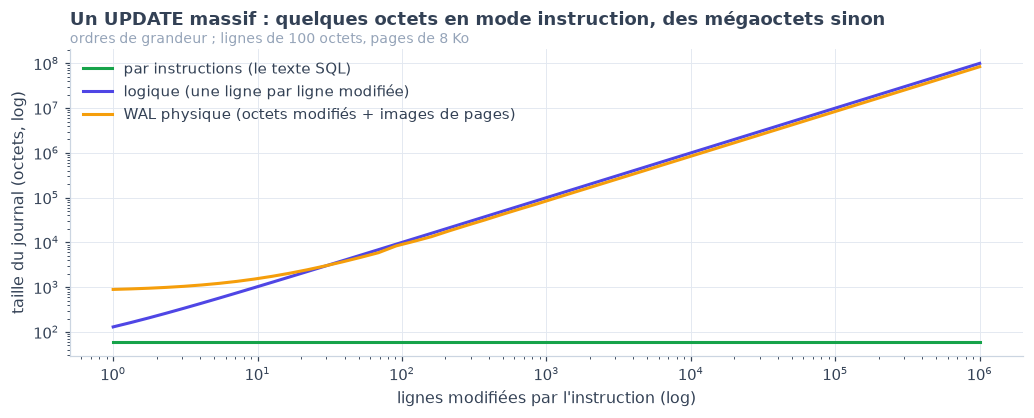

In [5]:
k = np.logspace(0, 6, 50)
stmt_size = np.full_like(k, 60.0)
row_size = 30 + 100 * k
wal_size = 50 * k + 0.1 * np.ceil(k / 80) * 8192 + 24 * k
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ax.loglog(k, stmt_size, color=GREEN, label="par instructions (le texte SQL)")
ax.loglog(k, row_size, color=INDIGO, label="logique (une ligne par ligne modifiée)")
ax.loglog(k, wal_size, color=AMBER, label="WAL physique (octets modifiés + images de pages)")
ax.set_xlabel("lignes modifiées par l'instruction (log)"); ax.set_ylabel("taille du journal (octets, log)")
ax.set_title("Un UPDATE massif : quelques octets en mode instruction, des mégaoctets sinon")
subtitle(ax, "ordres de grandeur ; lignes de 100 octets, pages de 8 Ko")
ax.legend()
plt.tight_layout(); plt.show()

Pour une mise à jour d'un million de lignes, le mode instruction envoie 60 octets là où
les deux autres envoient environ 100 Mo : c'est l'argument qui maintient la réplication
par instructions en vie pour certains usages. Le schéma suivant récapitule les trois
formats pour une même écriture.

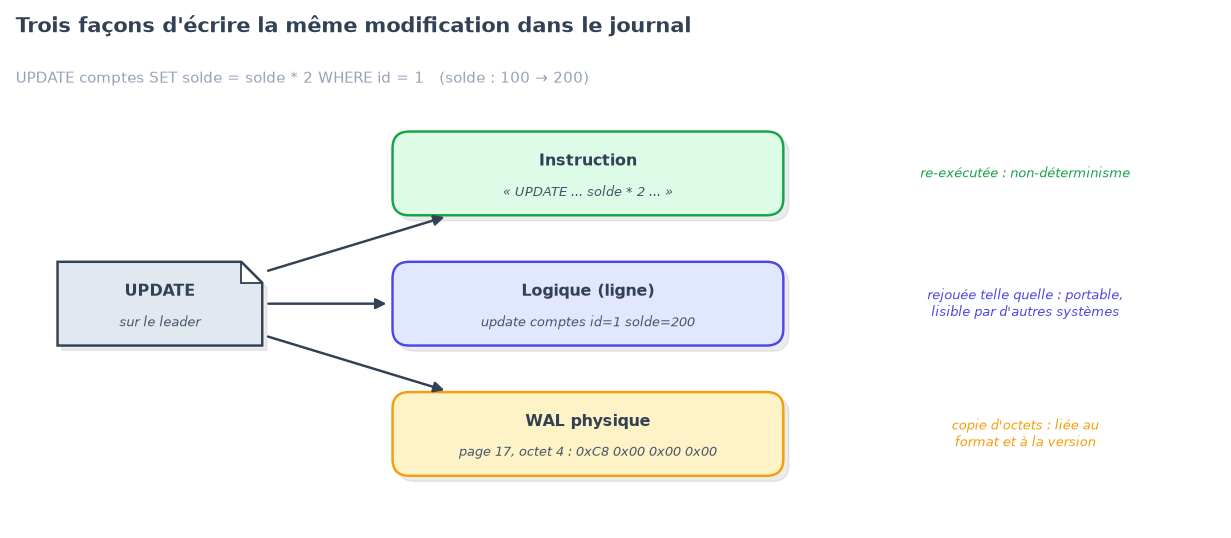

In [6]:
d = Diagram(13, 4.6, title="Trois façons d'écrire la même modification dans le journal",
            subtitle="UPDATE comptes SET solde = solde * 2 WHERE id = 1   (solde : 100 → 200)")
d.box("q", 1.6, 2.4, "UPDATE", sub="sur le leader", color=SLATE, w=2.2, kind="doc")
d.box("s", 6.2, 3.8, "Instruction", sub="« UPDATE ... solde * 2 ... »", color=GREEN, w=4.2)
d.box("l", 6.2, 2.4, "Logique (ligne)", sub="update comptes id=1 solde=200", color=INDIGO, w=4.2)
d.box("w", 6.2, 1.0, "WAL physique", sub="page 17, octet 4 : 0xC8 0x00 0x00 0x00", color=AMBER, w=4.2)
for n in "slw":
    d.arrow("q", n)
d.note(10.9, 3.8, "re-exécutée : non-déterminisme", color=GREEN, fontsize=8.5)
d.note(10.9, 2.4, "rejouée telle quelle : portable,\nlisible par d'autres systèmes", color=INDIGO, fontsize=8.5)
d.note(10.9, 1.0, "copie d'octets : liée au\nformat et à la version", color=AMBER, fontsize=8.5)
d.show()

> **À retenir.** Le journal logique, par lignes, fige les valeurs calculées par le
> leader : il est déterministe, portable entre versions et lisible par d'autres systèmes
> (capture des changements). Le mode instruction reste imbattable en volume pour les
> modifications massives.

## 4. Le retard de réplication (section *Problems with Replication Lag*)

Une charge typique du web lit beaucoup et écrit peu. D'où l'architecture de **montée en
charge des lectures** : beaucoup de suiveurs, les lectures réparties entre eux. Elle
n'est réaliste qu'en **asynchrone** (cours 1, section 2) : avec des dizaines de suiveurs
synchrones, la moindre panne bloquerait les écritures.

Un suiveur asynchrone peut être en retard : la même requête envoyée au même instant au
leader et à un suiveur peut donner deux réponses différentes. Si l'on cesse d'écrire,
les suiveurs finissent par rattraper : c'est la **cohérence à terme** (eventual
consistency). Mais « à terme » ne promet aucune borne : le **retard de réplication**
(replication lag) est d'ordinaire une fraction de seconde, et peut grimper à des secondes
ou des minutes si un nœud est saturé ou le réseau perturbé.

Le module modélise cela avec `rp.lag_cluster` : un leader valide des écritures (instants
de validation), et chaque suiveur applique le journal **dans l'ordre** avec un retard
aléatoire ; on peut aussi bloquer un suiveur pendant un intervalle (rattrapage, coupure).
Trois suiveurs dont le délai d'application propre à chaque écriture vaut en moyenne
10 ms, 50 ms et 200 ms (lois exponentielles) ; le dernier est en plus bloqué 20 s.
Comme le journal s'applique **dans l'ordre**, une écriture lente retient toutes celles
qui la suivent : le retard observé est plus grand que le délai moyen.

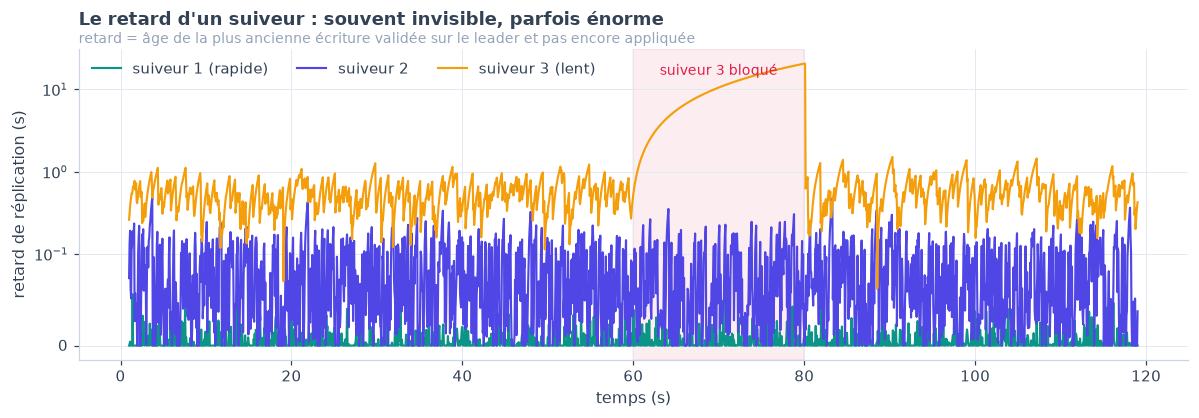

In [7]:
T = 120.0
wt = np.cumsum(rng.exponential(1 / 50, int(T * 50)))      # 50 écritures/s
wt = wt[wt < T]
cl = rp.lag_cluster(wt, 3, mean_lag=[0.01, 0.05, 0.2], stalls=[(2, 60, 80)], seed=1)
grid = np.linspace(1, T - 1, 2000)
fig, ax = plt.subplots(figsize=(11, 3.9))
for f, (c, lab) in enumerate([(TEAL, "suiveur 1 (rapide)"), (INDIGO, "suiveur 2"), (AMBER, "suiveur 3 (lent)")]):
    ax.plot(grid, [cl.lag_seconds(f, t) for t in grid], color=c, lw=1.4, label=lab)
ax.set_yscale("symlog", linthresh=0.1)
ax.axvspan(60, 80, color=ROSE, alpha=0.08); ax.text(70, 15, "suiveur 3 bloqué", ha="center", color=ROSE, fontsize=9)
ax.set_xlabel("temps (s)"); ax.set_ylabel("retard de réplication (s)")
ax.set_title("Le retard d'un suiveur : souvent invisible, parfois énorme")
subtitle(ax, "retard = âge de la plus ancienne écriture validée sur le leader et pas encore appliquée")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

En régime normal, le retard reste sous la seconde (avec des pointes pour le suiveur
lent, quand une écriture tarde et retient les suivantes) ; pendant le
blocage, le suiveur 3 accumule 20 s de retard, puis rattrape en quelques instants. Toute
lecture servie par lui pendant cet intervalle montre la base telle qu'elle était 20 s
plus tôt. Les trois sections suivantes décrivent les anomalies que cela produit, et les
garanties qui les excluent.

> **À retenir.** Lire sur des suiveurs asynchrones multiplie la capacité de lecture,
> mais expose des états passés : la cohérence à terme ne borne pas le retard.

## 5. Lire ses propres écritures (section *Reading Your Own Writes*)

Un utilisateur publie un commentaire (écriture au leader), puis recharge la page (lecture
sur un suiveur). Si ce suiveur est en retard, le commentaire a disparu : l'utilisateur
croit sa donnée perdue.

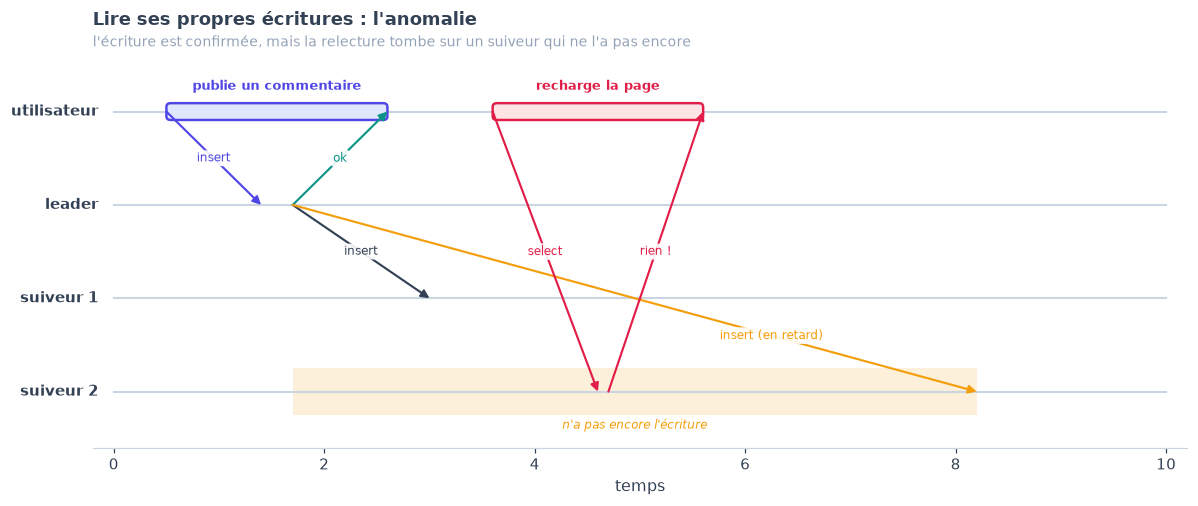

In [8]:
st = SpaceTime(["utilisateur", "leader", "suiveur 1", "suiveur 2"], t_max=10, width=11,
               title="Lire ses propres écritures : l'anomalie",
               subtitle="l'écriture est confirmée, mais la relecture tombe sur un suiveur qui ne l'a pas encore")
st.op("utilisateur", 0.5, 2.6, "publie un commentaire", color=INDIGO)
st.msg("utilisateur", 0.5, "leader", 1.4, "insert", color=INDIGO)
st.msg("leader", 1.7, "utilisateur", 2.6, "ok", color=TEAL)
st.msg("leader", 1.7, "suiveur 1", 3.0, "insert", color=SLATE)
st.msg("leader", 1.7, "suiveur 2", 8.2, "insert (en retard)", color=AMBER, label_pos=0.7)
st.op("utilisateur", 3.6, 5.6, "recharge la page", color=ROSE)
st.msg("utilisateur", 3.6, "suiveur 2", 4.6, "select", color=ROSE)
st.msg("suiveur 2", 4.7, "utilisateur", 5.6, "rien !", color=ROSE)
st.span("suiveur 2", 1.7, 8.2, "n'a pas encore l'écriture", color=AMBER, alpha=0.15)
st.show()

La garantie voulue s'appelle **cohérence lecture-après-écriture** (read-after-write, ou
read-your-writes) : un utilisateur voit toujours ses **propres** écritures après les
avoir faites. Elle ne promet rien sur celles des autres. Techniques possibles :

- lire au leader ce que l'utilisateur a pu modifier (son propre profil), le reste sur un
  suiveur ;
- pendant une **fenêtre** après sa dernière écriture (une minute par exemple), lire au
  leader ; ou écarter les suiveurs en retard de plus d'une minute ;
- le client retient un **jeton** : la position (LSN) de sa dernière écriture ; on ne
  lit que sur un suiveur au moins aussi avancé, sinon ailleurs ou on attend. Avec une
  horloge plutôt qu'un LSN, la synchronisation des horloges devient critique.

Comparons ces stratégies avec `rp.simulate_sessions` sur le groupe de la section 4 :
200 utilisateurs, chaque écriture suivie d'une relecture par son auteur après un temps de
réflexion de 200 ms en moyenne, puis de deux autres lectures.

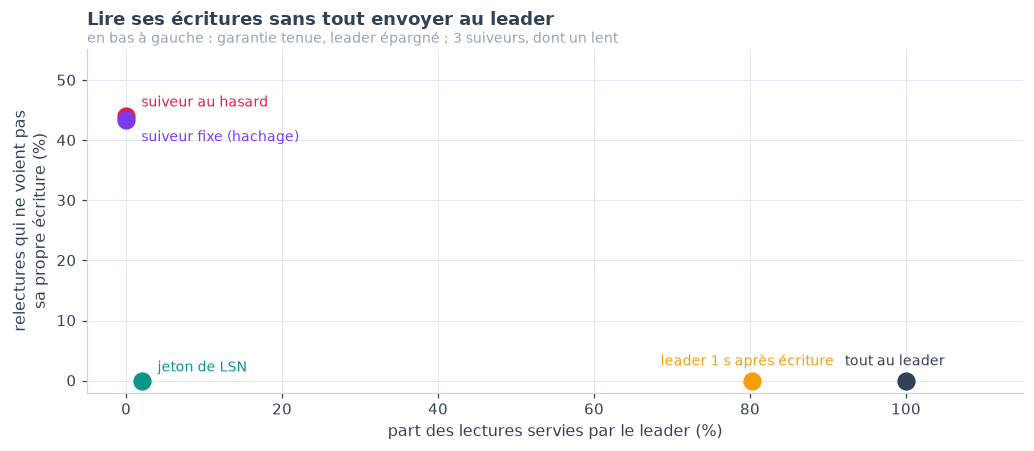

,relectures sans sa propre écriture,lectures qui remontent le temps,part des lectures au leader
stratégie,,,
suiveur au hasard,0.441,0.177,0.000
tout au leader,0.000,0.000,1.000
leader 1 s après écriture,0.000,0.031,0.803
suiveur fixe (hachage),0.434,0.000,0.000
jeton de LSN,0.000,0.000,0.021


In [9]:
owners = rng.integers(0, 200, len(wt)).tolist()
noms = {"aleatoire": "suiveur au hasard", "leader": "tout au leader", "fenetre": "leader 1 s après écriture",
        "collant": "suiveur fixe (hachage)", "jeton": "jeton de LSN"}
res = pd.DataFrame([rp.simulate_sessions(cl, owners, s, think=0.2, window=1.0, seed=2) for s in rp.STRATEGIES])
res["stratégie"] = res["strategie"].map(noms)
res = res.set_index("stratégie")[["anomalies_ryw", "anomalies_monotones", "part_leader"]]
res.columns = ["relectures sans sa propre écriture", "lectures qui remontent le temps", "part des lectures au leader"]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
offsets = {"suiveur au hasard": (10, 6), "suiveur fixe (hachage)": (10, -14), "tout au leader": (-40, 10),
           "leader 1 s après écriture": (-60, 10), "jeton de LSN": (10, 6)}
for (name, row), c in zip(res.iterrows(), [ROSE, SLATE, AMBER, VIOLET, TEAL]):
    ax.scatter(row.iloc[2] * 100, row.iloc[0] * 100, s=120, color=c, zorder=3)
    ax.annotate(name, (row.iloc[2] * 100, row.iloc[0] * 100), offsets[name], textcoords="offset points", fontsize=9, color=c)
ax.set_xlabel("part des lectures servies par le leader (%)")
ax.set_ylabel("relectures qui ne voient pas\nsa propre écriture (%)")
ax.set_xlim(-5, 115); ax.set_ylim(-2, res.iloc[:, 0].max() * 100 * 1.25)
ax.set_title("Lire ses écritures sans tout envoyer au leader")
subtitle(ax, "en bas à gauche : garantie tenue, leader épargné ; 3 suiveurs, dont un lent")
plt.tight_layout(); plt.show()
res.round(3)

Lire au hasard sur un suiveur fait rater sa propre écriture dans une proportion élevée
des relectures, et fixer le suiveur par hachage n'y change rien (un utilisateur attaché
au suiveur lent le reste). Tout lire au leader règle le problème en supprimant l'intérêt
des suiveurs. La fenêtre fonctionne, mais envoie au leader une grosse part des lectures
dans cette charge où chacun relit juste après avoir écrit. Le **jeton de LSN** obtient
zéro anomalie en n'envoyant au leader qu'une petite part des lectures : le client sait
exactement de quelle position il a besoin.

**Plusieurs appareils** compliquent l'affaire : si l'utilisateur écrit depuis son
ordinateur et relit sur son téléphone, le jeton doit être **centralisé** (le téléphone
ne connaît pas la dernière écriture de l'ordinateur), et les deux appareils, qui passent
par des réseaux différents, peuvent être routés vers des régions différents : il faut
parfois router toutes les requêtes d'un même utilisateur vers le même endroit.

**Régions et zones** (encadré *Regions and Availability Zones*). Le livre appelle
**région** un ensemble de centres de données d'un même lieu géographique ; chacun est
une **zone de disponibilité**, avec son alimentation et son refroidissement. Les zones
d'une région sont reliées par un réseau très rapide : un système réparti sur plusieurs
zones se comporte presque comme s'il était dans une seule, et survit à la perte d'une
zone. Survivre à la perte d'une région entière impose de se répartir entre régions, avec
plus de latence, moins de débit et une facture réseau plus élevée.

> **À retenir.** « Lire ses écritures » se garantit en dirigeant certaines lectures vers
> le leader, ou mieux en transportant un jeton de position : le client exige une
> réplique au moins aussi avancée que sa dernière écriture.

## 6. Lectures monotones (section *Monotonic Reads*)

Deuxième anomalie : **remonter le temps**. Un utilisateur recharge une page ; la première
requête tombe sur un suiveur à jour et montre un nouveau commentaire, la seconde tombe sur
un suiveur en retard et le commentaire **disparaît**. Ne jamais l'avoir vu serait moins
troublant que de le voir puis de ne plus le voir.

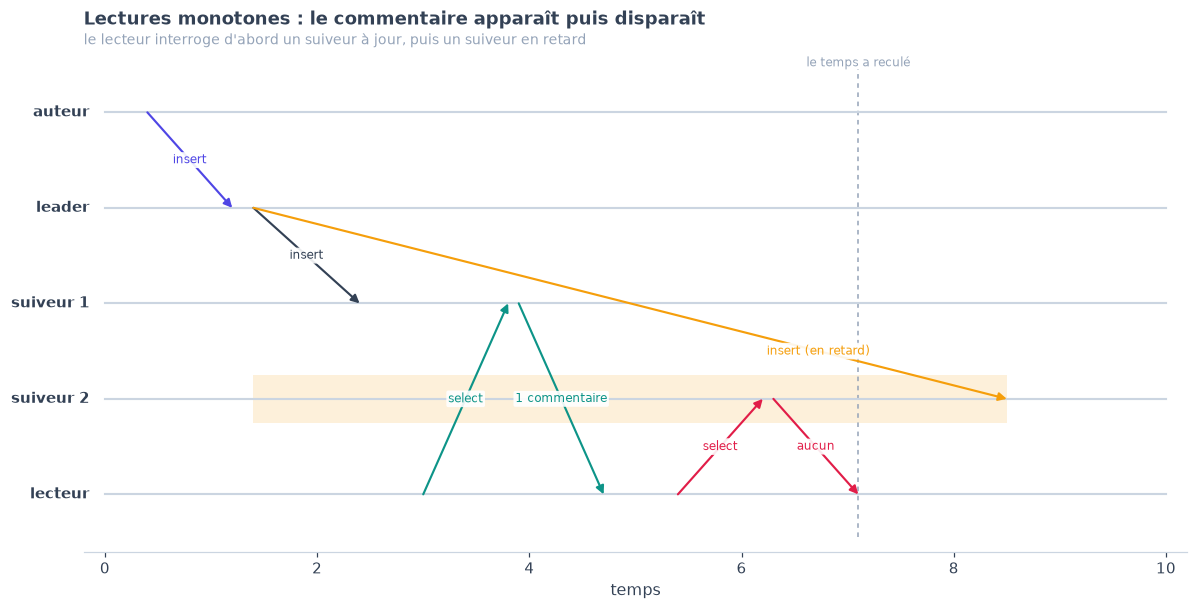

In [10]:
st = SpaceTime(["auteur", "leader", "suiveur 1", "suiveur 2", "lecteur"], t_max=10, width=11,
               title="Lectures monotones : le commentaire apparaît puis disparaît",
               subtitle="le lecteur interroge d'abord un suiveur à jour, puis un suiveur en retard")
st.msg("auteur", 0.4, "leader", 1.2, "insert", color=INDIGO)
st.msg("leader", 1.4, "suiveur 1", 2.4, "insert", color=SLATE)
st.msg("leader", 1.4, "suiveur 2", 8.5, "insert (en retard)", color=AMBER, label_pos=0.75)
st.msg("lecteur", 3.0, "suiveur 1", 3.8, "select", color=TEAL)
st.msg("suiveur 1", 3.9, "lecteur", 4.7, "1 commentaire", color=TEAL)
st.msg("lecteur", 5.4, "suiveur 2", 6.2, "select", color=ROSE)
st.msg("suiveur 2", 6.3, "lecteur", 7.1, "aucun", color=ROSE)
st.span("suiveur 2", 1.4, 8.5, "", color=AMBER, alpha=0.15)
st.vline(7.1, "le temps a reculé")
st.show()

Les **lectures monotones** garantissent que cela n'arrive pas : on peut lire une valeur
ancienne, mais une suite de lectures d'un même utilisateur ne revient jamais à un état
plus ancien qu'un état déjà vu. C'est plus faible que la cohérence forte, plus fort que la
cohérence à terme. Le moyen le plus simple : chaque utilisateur lit **toujours sur la
même réplique** (choisie par hachage de son identifiant), jusqu'à ce que celle-ci tombe
en panne. Dans le tableau précédent, la stratégie « suiveur fixe » a bien zéro lecture
qui remonte le temps, tout comme le jeton (qui exige une réplique au moins aussi avancée
que tout ce que le client a vu).

**Quand l'anomalie devient-elle fréquente ?** Faisons varier le retard moyen du suiveur
lent, les deux autres restant rapides, avec un routage aléatoire.

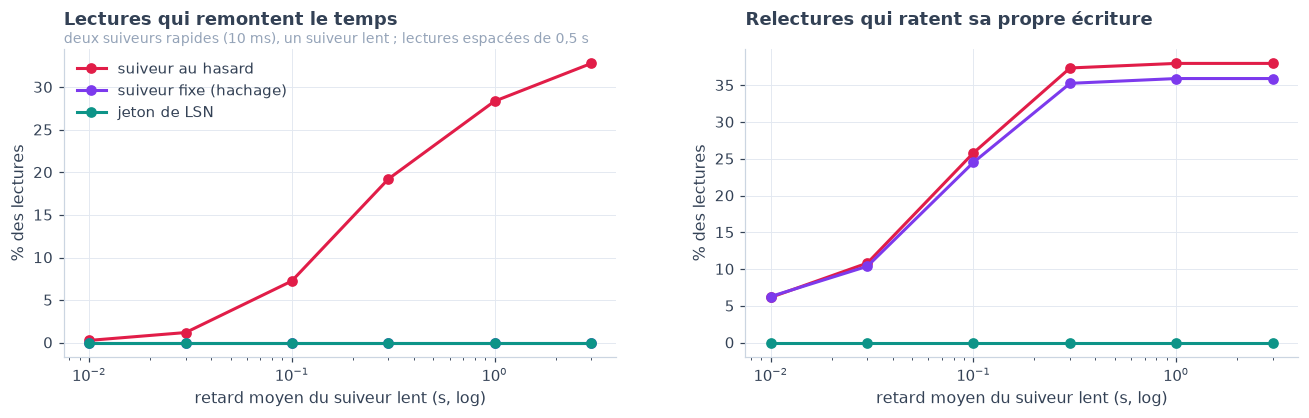

In [11]:
lags = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
rows = []
for lag in lags:
    c2 = rp.lag_cluster(wt, 3, mean_lag=[0.01, 0.01, lag], seed=3)
    for s in ["aleatoire", "collant", "jeton"]:
        r = rp.simulate_sessions(c2, owners, s, think=0.2, read_gap=0.5, seed=4)
        rows.append({"retard du suiveur lent (s)": lag, "stratégie": noms[s], "monotonie violée (%)": 100 * r["anomalies_monotones"],
                     "relecture ratée (%)": 100 * r["anomalies_ryw"]})
M = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharex=True)
for (s, g), c in zip(M.groupby("stratégie", sort=False), [ROSE, VIOLET, TEAL]):
    axes[0].plot(g.iloc[:, 0], g["monotonie violée (%)"], "o-", color=c, label=s)
    axes[1].plot(g.iloc[:, 0], g["relecture ratée (%)"], "o-", color=c, label=s)
for ax, t in zip(axes, ["Lectures qui remontent le temps", "Relectures qui ratent sa propre écriture"]):
    ax.set_xscale("log"); ax.set_xlabel("retard moyen du suiveur lent (s, log)"); ax.set_ylabel("% des lectures"); ax.set_title(t)
axes[0].legend()
subtitle(axes[0], "deux suiveurs rapides (10 ms), un suiveur lent ; lectures espacées de 0,5 s")
finish(fig); plt.show()

Tant que le suiveur lent reste sous quelques dizaines de millisecondes, les anomalies
sont rares avec un routage aléatoire ; dès que son retard approche l'intervalle entre deux
lectures d'un même utilisateur (0,5 s ici), elles explosent. Le suiveur fixe supprime les
retours en arrière mais pas les relectures ratées (un tiers des utilisateurs est attaché
au suiveur lent) ; le jeton supprime les deux.

> **À retenir.** Les lectures monotones interdisent de « voir le temps reculer » ;
> lire toujours sur la même réplique suffit. Les anomalies dépendent du rapport entre le
> retard et l'intervalle entre deux lectures d'un même utilisateur.

## 7. Lectures à préfixe cohérent (section *Consistent Prefix Reads*)

Troisième anomalie : la **causalité violée**. Monsieur Poons demande à Madame Cake
jusqu'où elle voit dans l'avenir ; elle répond « une dizaine de secondes ». Un
observateur qui lit la conversation à travers des suiveurs peut lire la **réponse avant
la question**, si les deux messages ont emprunté des chemins de réplication différents.
Cela arrive surtout dans une base découpée en shards (chapitre 7) :
chaque shard a son propre leader et ses propres suiveurs, sans ordre global des
écritures.

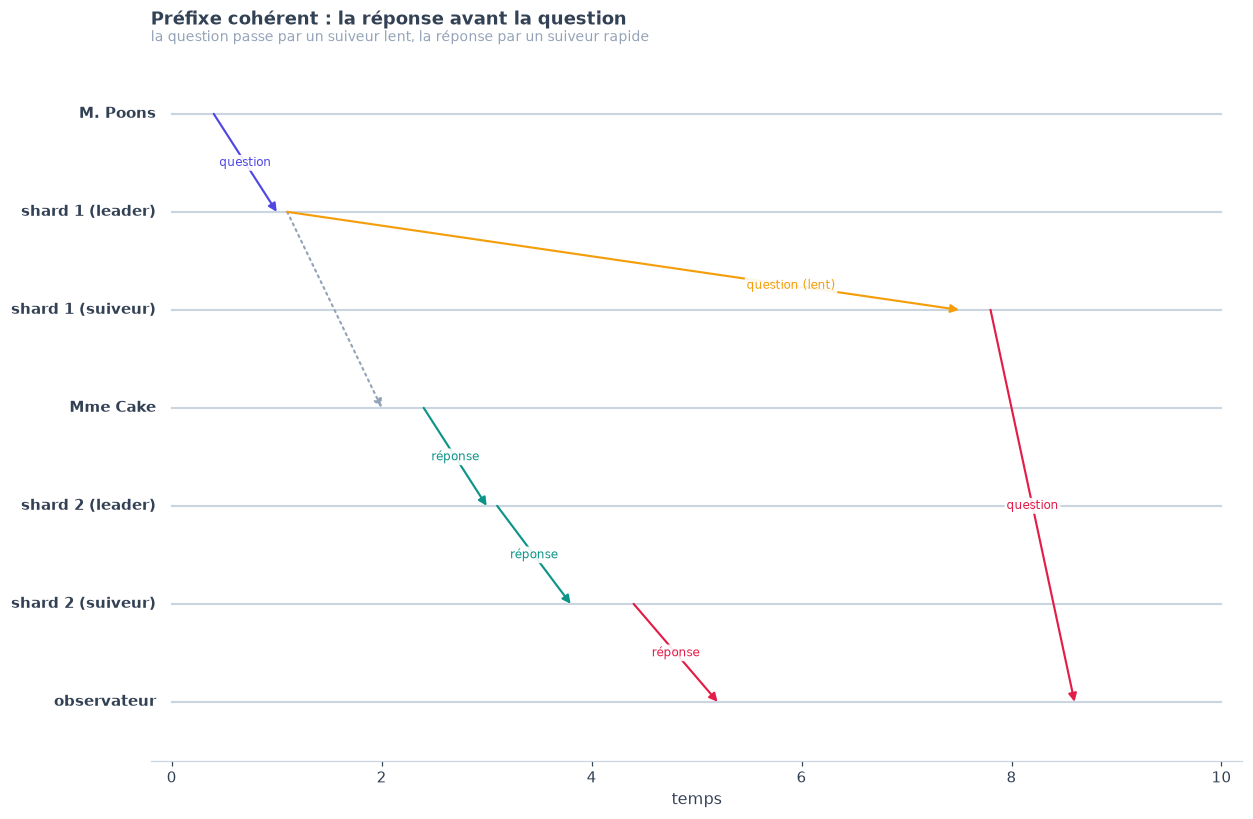

In [12]:
st = SpaceTime(["M. Poons", "shard 1 (leader)", "shard 1 (suiveur)",
                "Mme Cake", "shard 2 (leader)", "shard 2 (suiveur)", "observateur"],
               t_max=10, width=11.5, title="Préfixe cohérent : la réponse avant la question",
               subtitle="la question passe par un suiveur lent, la réponse par un suiveur rapide")
st.msg("M. Poons", 0.4, "shard 1 (leader)", 1.0, "question", color=INDIGO)
st.msg("shard 1 (leader)", 1.1, "Mme Cake", 2.0, "", color=GRAY, style="dotted")
st.msg("shard 1 (leader)", 1.1, "shard 1 (suiveur)", 7.5, "question (lent)", color=AMBER, label_pos=0.75)
st.msg("Mme Cake", 2.4, "shard 2 (leader)", 3.0, "réponse", color=TEAL)
st.msg("shard 2 (leader)", 3.1, "shard 2 (suiveur)", 3.8, "réponse", color=TEAL)
st.msg("shard 2 (suiveur)", 4.4, "observateur", 5.2, "réponse", color=ROSE)
st.msg("shard 1 (suiveur)", 7.8, "observateur", 8.6, "question", color=ROSE)
st.show()

La garantie de **préfixe cohérent** dit que si des écritures surviennent dans un certain
ordre, tout lecteur les voit apparaître dans cet ordre. Un système qui applique toutes
les écritures dans un ordre unique la fournit gratuitement (c'est le cas d'un leader
unique). Avec plusieurs shards indépendants, on la perd : l'observateur voit une partie
de la base dans un état récent et une autre dans un état ancien.

Quantifions : la question est écrite à l'instant 0 dans la shard 1, la réponse $\delta$
plus tard dans la shard 2 ; un observateur lit les deux suiveurs à un instant
aléatoire dans les deux secondes qui suivent la réponse. Il voit la réponse sans la question si le suiveur 2 a appliqué la réponse et
pas le suiveur 1 la question. Avec des retards exponentiels de moyennes $m_1$ et $m_2$
observés au même instant $t$, la probabilité que la réponse soit visible sans la question
vaut $P(L_2 < t - \delta,\ L_1 > t)$ ; simulons-la en fonction du temps de réponse
$\delta$ de Madame Cake.

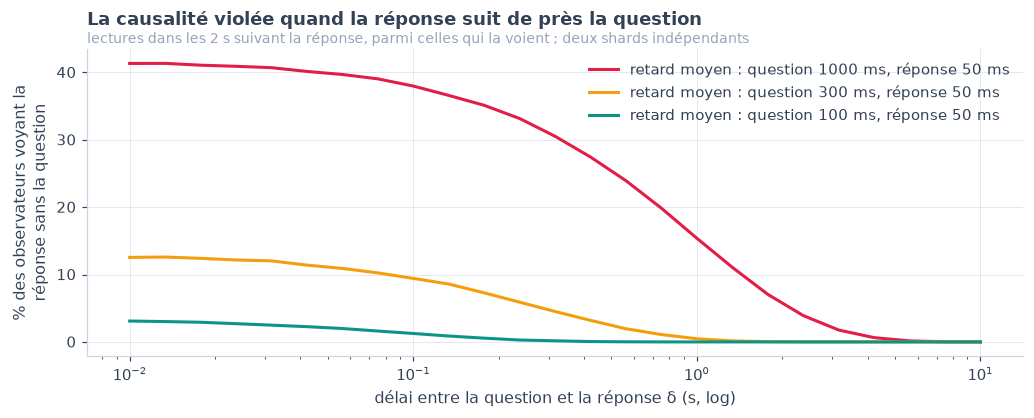

In [13]:
def p_anomalie(delta, m1, m2, n=200000, rng=np.random.default_rng(5)):
    L1 = rng.exponential(m1, n); L2 = rng.exponential(m2, n)
    t = delta + rng.uniform(0, 2.0, n)                       # lecture dans les 2 s qui suivent la réponse
    vois_reponse = t >= delta + L2
    vois_question = t >= L1
    return (vois_reponse & ~vois_question).sum() / max(vois_reponse.sum(), 1)

deltas = np.logspace(-2, 1, 25)
fig, ax = plt.subplots(figsize=(9.5, 3.9))
for (m1, m2), c in [((1.0, 0.05), ROSE), ((0.3, 0.05), AMBER), ((0.1, 0.05), TEAL)]:
    ax.plot(deltas, [100 * p_anomalie(d_, m1, m2) for d_ in deltas], color=c,
            label=f"retard moyen : question {m1 * 1000:.0f} ms, réponse {m2 * 1000:.0f} ms")
ax.set_xscale("log")
ax.set_xlabel("délai entre la question et la réponse δ (s, log)")
ax.set_ylabel("% des observateurs voyant la\nréponse sans la question")
ax.set_title("La causalité violée quand la réponse suit de près la question")
subtitle(ax, "lectures dans les 2 s suivant la réponse, parmi celles qui la voient ; deux shards indépendants")
ax.legend()
plt.tight_layout(); plt.show()

Quand la réponse suit la question de près (une conversation en ligne, une mise à jour
qui en déclenche une autre), une part notable des lecteurs voit l'effet avant la cause ;
l'anomalie disparaît quand le délai dépasse largement le retard de réplication. Parades :
écrire les données causalement liées dans la même shard (pas toujours possible
efficacement), ou suivre explicitement les dépendances causales, ce que permettent les
vecteurs de versions (cours 5) et la relation « arrivé avant » (chapitre 10).

> **À retenir.** Le préfixe cohérent garantit qu'on voit les écritures dans l'ordre où
> elles ont eu lieu. Un leader unique le donne gratuitement ; des shards répliqués
> indépendamment le perdent.

## 8. Choisir une parade (section *Solutions for Replication Lag*)

Face à un système cohérent à terme, la bonne question est : que se passe-t-il si le
retard monte à plusieurs minutes, voire des heures ? Si la réponse est « rien de grave »,
tant mieux. Sinon, il faut une garantie plus forte, et **faire comme si la réplication
était synchrone alors qu'elle ne l'est pas** est la recette des ennuis. Récapitulatif :

In [14]:
G = pd.DataFrame({
    "garantie": ["lire ses écritures", "lectures monotones", "préfixe cohérent"],
    "anomalie exclue": ["sa propre écriture invisible", "le temps qui recule", "l'effet avant la cause"],
    "portée": ["un utilisateur, ses écritures", "un utilisateur, ses lectures successives", "tous les lecteurs, écritures liées"],
    "parade typique": ["lire au leader / jeton de LSN", "réplique fixe par utilisateur / jeton", "même shard / suivi de la causalité"],
}).set_index("garantie")
G

,anomalie exclue,portée,parade typique
garantie,,,
lire ses écritures,sa propre écriture invisible,"un utilisateur, ses écritures",lire au leader / jeton de LSN
lectures monotones,le temps qui recule,"un utilisateur, ses lectures successives",réplique fixe par utilisateur / jeton
préfixe cohérent,l'effet avant la cause,"tous les lecteurs, écritures liées",même shard / suivi de la causalité


Gérer ces garanties dans le code applicatif est complexe et facile à rater. Le modèle le
plus simple pour le développeur est une base qui offre directement des garanties fortes
(transactions, chapitre 8 ; linéarisabilité, chapitre
10), pour raisonner comme s'il n'y avait qu'un seul nœud.

Au début des années 2010, le mouvement NoSQL soutenait que ces garanties limitaient le
passage à l'échelle et que les grands systèmes devraient se contenter de cohérence à
terme. Depuis, des bases dites **NewSQL** combinent cohérence forte, transactions et
tolérance aux pannes d'une base distribuée. Les formes de réplication plus faibles
gardent pourtant leurs atouts : meilleure résistance aux coupures réseau et coût moindre
que les systèmes transactionnels. Ce sont elles que décrivent les cours 3 à 5.

> **À retenir.** Il faut décider explicitement du comportement de l'application sous un
> fort retard de réplication. Les garanties de session (lire ses écritures, lectures
> monotones, préfixe cohérent) se construisent au-dessus d'une base cohérente à terme ;
> une base à garanties fortes évite d'avoir à les construire.

## Synthèse

- Trois formats de journal : instructions (compact, mais non-déterminisme), WAL physique
  (copies exactes, mais couplage à la version du moteur), logique par lignes
  (déterministe, portable, base de la capture des changements, chapitre 12).
- La réplication asynchrone vers de nombreux suiveurs permet de servir beaucoup de
  lectures, au prix d'un retard sans borne : la cohérence à terme.
- Trois anomalies, trois garanties : lire ses écritures (jeton de position), lectures
  monotones (réplique fixe), préfixe cohérent (même shard, causalité suivie).

Liens : la causalité et la relation « arrivé avant » reviennent au cours 5 et au
chapitre 10 ; les shards au chapitre 7 ; le lab de ce chapitre
mesure le retard réel d'une réplique PostgreSQL et décode son journal logique.